In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

# Para reproducibilidad
SEED = 123
np.random.seed(SEED)
import tensorflow as tf
tf.random.set_seed(SEED)

# Cargar MNIST
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train_full.shape, X_test.shape, y_train_full.shape, y_test.shape


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


((60000, 28, 28), (10000, 28, 28), (60000,), (10000,))

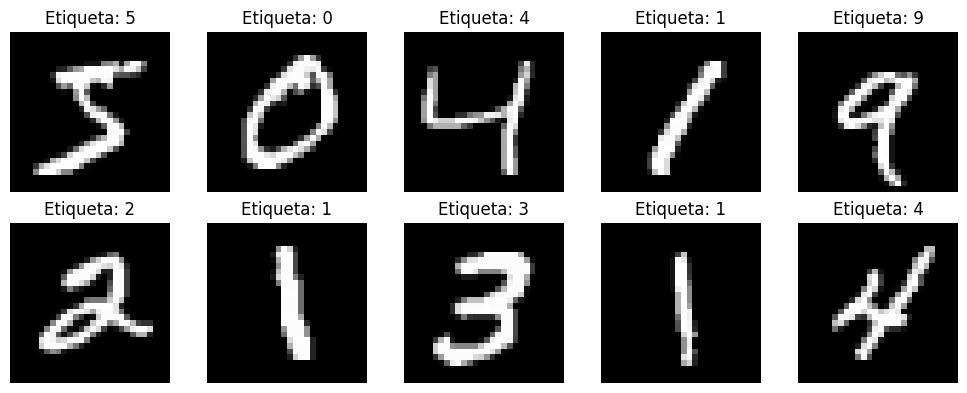

Dígito 0: 5923 imágenes
Dígito 1: 6742 imágenes
Dígito 2: 5958 imágenes
Dígito 3: 6131 imágenes
Dígito 4: 5842 imágenes
Dígito 5: 5421 imágenes
Dígito 6: 5918 imágenes
Dígito 7: 6265 imágenes
Dígito 8: 5851 imágenes
Dígito 9: 5949 imágenes


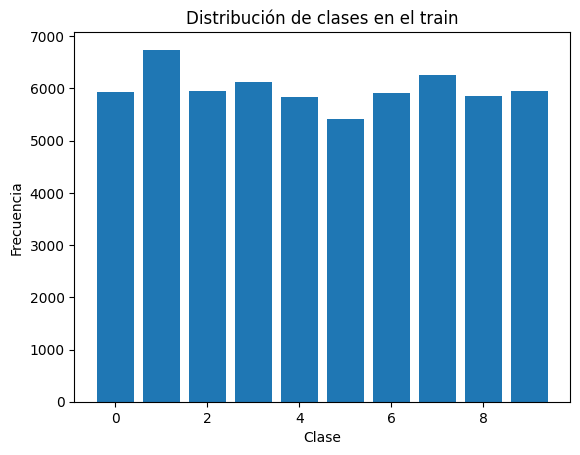

In [2]:
# Mostrar algunas imágenes de ejemplo
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(f"Etiqueta: {y_train_full[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# Distribución de clases
unique, counts = np.unique(y_train_full, return_counts=True)
for u, c in zip(unique, counts):
    print(f"Dígito {u}: {c} imágenes")

plt.figure()
plt.bar(unique, counts)
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.title("Distribución de clases en el train")
plt.show()


In [3]:
# Normalizar a [0,1] y aplanar a vectores de 784 píxeles
X_train_full_norm = X_train_full.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

n_pixels = 28 * 28
X_train_full_flat = X_train_full_norm.reshape(-1, n_pixels)
X_test_flat = X_test_norm.reshape(-1, n_pixels)

# One-hot encoding de las etiquetas
num_classes = 10
y_train_full_cat = to_categorical(y_train_full, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

# Split train / validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full_flat,
    y_train_full_cat,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

X_train.shape, X_val.shape, X_test_flat.shape


((48000, 784), (12000, 784), (10000, 784))

In [4]:
def create_model(n_units=128, activation="relu", dropout_rate=0.3, optimizer="adam"):
    model = models.Sequential()
    model.add(layers.Input(shape=(n_pixels,)))
    model.add(layers.Dense(n_units, activation=activation))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(n_units // 2, activation=activation))
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        loss="categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"]
    )
    return model


In [5]:
from tensorflow.keras.callbacks import EarlyStopping

# Subconjunto para búsqueda (por ejemplo 15000 muestras)
subset_size = 15000
X_train_sub = X_train[:subset_size]
y_train_sub = y_train[:subset_size]

param_grid = {
    "n_units": [64, 128],
    "activation": ["relu", "tanh"],
    "dropout_rate": [0.3, 0.5],
    "optimizer": ["adam"]  # Podrías agregar 'rmsprop' si tenés tiempo
}

best_val_acc = 0.0
best_params = None
histories = {}

es = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

config_id = 0

for n_units in param_grid["n_units"]:
    for activation in param_grid["activation"]:
        for dropout_rate in param_grid["dropout_rate"]:
            for optimizer in param_grid["optimizer"]:
                config_id += 1
                print(f"\nConfig {config_id}: units={n_units}, act={activation}, "
                      f"dropout={dropout_rate}, opt={optimizer}")

                model = create_model(
                    n_units=n_units,
                    activation=activation,
                    dropout_rate=dropout_rate,
                    optimizer=optimizer
                )

                history = model.fit(
                    X_train_sub,
                    y_train_sub,
                    validation_data=(X_val, y_val),
                    epochs=15,
                    batch_size=128,
                    callbacks=[es],
                    verbose=0
                )

                val_acc = max(history.history["val_accuracy"])
                print(f"Mejor val_accuracy: {val_acc:.4f}")

                config_key = (n_units, activation, dropout_rate, optimizer)
                histories[config_key] = history.history

                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_params = {
                        "n_units": n_units,
                        "activation": activation,
                        "dropout_rate": dropout_rate,
                        "optimizer": optimizer
                    }

print("\nMejores hiperparámetros encontrados:")
print(best_params)
print(f"Mejor val_accuracy: {best_val_acc:.4f}")



Config 1: units=64, act=relu, dropout=0.3, opt=adam
Mejor val_accuracy: 0.9513

Config 2: units=64, act=relu, dropout=0.5, opt=adam
Mejor val_accuracy: 0.9475

Config 3: units=64, act=tanh, dropout=0.3, opt=adam
Mejor val_accuracy: 0.9398

Config 4: units=64, act=tanh, dropout=0.5, opt=adam
Mejor val_accuracy: 0.9291

Config 5: units=128, act=relu, dropout=0.3, opt=adam
Mejor val_accuracy: 0.9622

Config 6: units=128, act=relu, dropout=0.5, opt=adam
Mejor val_accuracy: 0.9577

Config 7: units=128, act=tanh, dropout=0.3, opt=adam
Mejor val_accuracy: 0.9478

Config 8: units=128, act=tanh, dropout=0.5, opt=adam
Mejor val_accuracy: 0.9425

Mejores hiperparámetros encontrados:
{'n_units': 128, 'activation': 'relu', 'dropout_rate': 0.3, 'optimizer': 'adam'}
Mejor val_accuracy: 0.9622


Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7684 - loss: 0.7663 - val_accuracy: 0.9490 - val_loss: 0.1729
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9376 - loss: 0.2108 - val_accuracy: 0.9588 - val_loss: 0.1292
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9539 - loss: 0.1565 - val_accuracy: 0.9678 - val_loss: 0.1060
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9599 - loss: 0.1307 - val_accuracy: 0.9705 - val_loss: 0.0963
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9652 - loss: 0.1137 - val_accuracy: 0.9723 - val_loss: 0.0883
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9702 - loss: 0.0988 - val_accuracy: 0.9728 - val_loss: 0.0870
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9715 - loss: 0.0914 - val_accuracy: 0.9758 - val_loss: 0.0815
Epoch 8/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9742 - loss: 0.0817 - val_accuracy: 0.

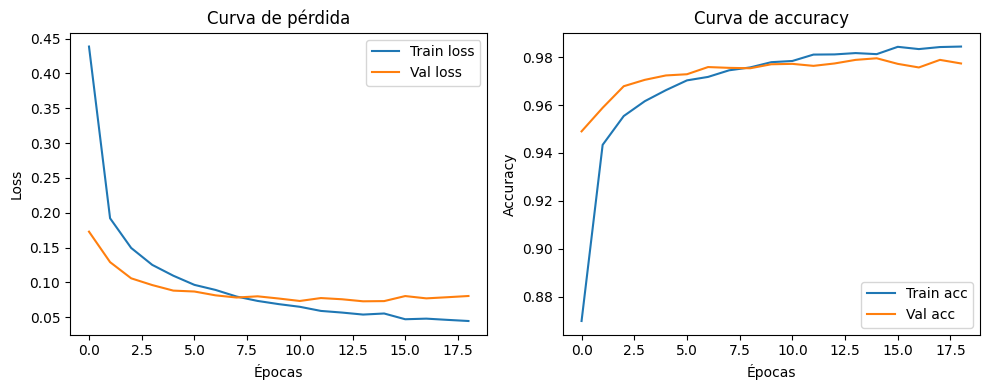

In [6]:
# Unir train + val para el modelo definitivo de producción
X_prod = np.vstack([X_train, X_val])
y_prod = np.vstack([y_train, y_val])

final_model = create_model(**best_params)

es_final = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_final = final_model.fit(
    X_prod,
    y_prod,
    validation_split=0.1,   # usamos un 10% de hold-out solo para monitoreo
    epochs=30,
    batch_size=128,
    callbacks=[es_final],
    verbose=1
)

# Curvas de aprendizaje
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history_final.history["loss"], label="Train loss")
plt.plot(history_final.history["val_loss"], label="Val loss")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.title("Curva de pérdida")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_final.history["accuracy"], label="Train acc")
plt.plot(history_final.history["val_accuracy"], label="Val acc")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.title("Curva de accuracy")
plt.legend()

plt.tight_layout()
plt.show()


In [7]:
# Evaluación en test
y_test_pred_prob = final_model.predict(X_test_flat)
y_test_pred = np.argmax(y_test_pred_prob, axis=1)

test_acc = accuracy_score(y_test, y_test_pred)
print(f"Accuracy en test: {test_acc:.4f}")

# Intervalo de confianza del 95% para la proporción (approx normal)
n_test = len(y_test)
p = test_acc
z = 1.96

std_error = np.sqrt(p * (1 - p) / n_test)
ci_lower = p - z * std_error
ci_upper = p + z * std_error

print(f"IC 95% para la accuracy: [{ci_lower:.4f}, {ci_upper:.4f}]")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy en test: 0.9783
IC 95% para la accuracy: [0.9754, 0.9812]


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Índice 50: etiqueta real = 6, predicción = 6


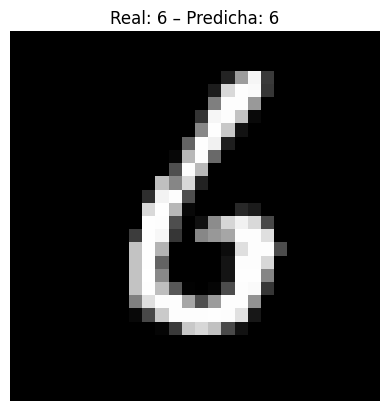

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Índice 150: etiqueta real = 9, predicción = 9


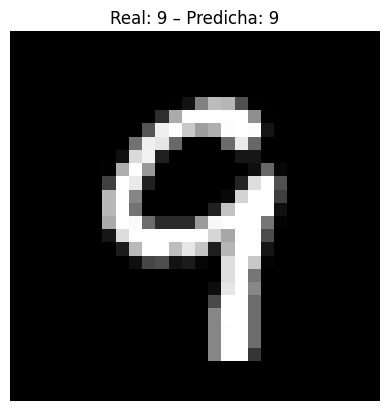

In [8]:
idxs = [50, 150]

for idx in idxs:
    img = X_test_flat[idx].reshape(1, -1)
    pred = np.argmax(final_model.predict(img), axis=1)[0]
    print(f"Índice {idx}: etiqueta real = {y_test[idx]}, predicción = {pred}")

    plt.figure()
    plt.imshow(X_test[idx], cmap="gray")
    plt.title(f"Real: {y_test[idx]} – Predicha: {pred}")
    plt.axis("off")
    plt.show()


In [9]:
final_model.save("mnist_model_produccion.h5")
print("Modelo guardado como mnist_model_produccion.h5")


Modelo guardado como mnist_model_produccion.h5


In [10]:
from sklearn.preprocessing import StandardScaler

# Para PCA, conviene centrar/escalar
scaler_pca = StandardScaler(with_mean=True, with_std=True)

X_train_full_scaled = scaler_pca.fit_transform(X_train_full_flat)
X_test_scaled = scaler_pca.transform(X_test_flat)

# PCA a 200 componentes
pca = PCA(n_components=200, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_full_scaled)
X_test_pca = pca.transform(X_test_scaled)

X_train_pca.shape, X_test_pca.shape


((60000, 200), (10000, 200))

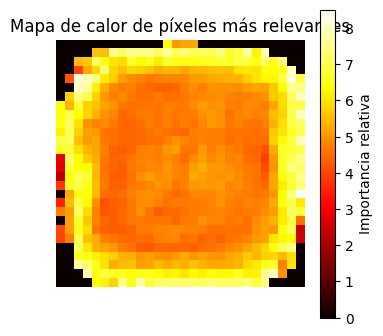

In [11]:
# pca.components_.shape = (200, 784)
# Importancia de cada píxel = suma de |componentes| a lo largo de las 200 componentes
pixel_importance = np.sum(np.abs(pca.components_), axis=0)
heatmap = pixel_importance.reshape(28, 28)

plt.figure(figsize=(4,4))
plt.imshow(heatmap, cmap="hot")
plt.colorbar(label="Importancia relativa")
plt.title("Mapa de calor de píxeles más relevantes")
plt.axis("off")
plt.show()


In [12]:
def create_model_pca(n_units=128, activation="relu", dropout_rate=0.3, optimizer="adam"):
    model = models.Sequential()
    model.add(layers.Input(shape=(200,)))
    model.add(layers.Dense(n_units, activation=activation))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(n_units // 2, activation=activation))
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        loss="categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"]
    )
    return model

# One-hot de todo el train_full para PCA
y_train_full_cat = to_categorical(y_train_full, num_classes)

X_train_pca_tr, X_val_pca, y_train_pca_tr, y_val_pca = train_test_split(
    X_train_pca,
    y_train_full_cat,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

model_pca = create_model_pca(
    n_units=best_params["n_units"],
    activation=best_params["activation"],
    dropout_rate=best_params["dropout_rate"],
    optimizer=best_params["optimizer"]
)

es_pca = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_pca = model_pca.fit(
    X_train_pca_tr,
    y_train_pca_tr,
    validation_data=(X_val_pca, y_val_pca),
    epochs=30,
    batch_size=128,
    callbacks=[es_pca],
    verbose=1
)

# Evaluar en test reducido
y_test_pca_pred_prob = model_pca.predict(X_test_pca)
y_test_pca_pred = np.argmax(y_test_pca_pred_prob, axis=1)

test_acc_pca = accuracy_score(y_test, y_test_pca_pred)
print(f"Accuracy en test con 200 componentes PCA: {test_acc_pca:.4f}")

# Comparar con modelo original
print(f"Accuracy modelo original (784 píxeles): {test_acc:.4f}")
print(f"Accuracy modelo reducido (200 componentes): {test_acc_pca:.4f}")


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6662 - loss: 1.1258 - val_accuracy: 0.9283 - val_loss: 0.2540
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9090 - loss: 0.3188 - val_accuracy: 0.9438 - val_loss: 0.2013
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9279 - loss: 0.2493 - val_accuracy: 0.9532 - val_loss: 0.1707
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9391 - loss: 0.2098 - val_accuracy: 0.9572 - val_loss: 0.1559
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9477 - loss: 0.1758 - val_accuracy: 0.9591 - val_loss: 0.1494
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9542 - loss: 0.1600 - val_accuracy: 0.9630 - val_loss: 0.1368
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9579 - loss: 0.1454 - val_accuracy: 0.9647 - val_loss: 0.1325
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9569 - loss: 0.1403 - val_accuracy: 0.

#  Modelo Entrenado sobre MNIST

Este modelo constituye la primera parte del trabajo, donde se implementa una red neuronal totalmente conectada (Multilayer Perceptron – MLP) entrenada sobre el dataset **MNIST**, compuesto por 60.000 imágenes de entrenamiento y 10.000 de prueba.

---

##  1. Análisis Exploratorio de Datos (EDA)

Antes del entrenamiento se realizó un EDA básico que incluyó:

- Visualización aleatoria de dígitos para verificar estructura.
- Confirmación del formato: imágenes **28×28**, escala de grises.
- Revisión de la distribución de clases (balanceada).
- Normalización de los datos al rango **[0,1]**.
- Aplanamiento de las imágenes a vectores de **784 variables**.

Esto permitió validar que los datos fueran consistentes y aptos para el modelo.

---

##  2. Ingeniería de Variables

Se aplicaron las siguientes transformaciones:

- **Normalización** dividiendo cada píxel por 255.
- **Aplanado** de 28×28 a 1×784.
- **One-hot encoding** de etiquetas.
- División del dataset en:
  - **Entrenamiento:** 48.000 imágenes  
  - **Validación:** 12.000 imágenes  
  - **Prueba:** 10.000 imágenes

Estas transformaciones permiten que la red neuronal reciba entradas numéricas estandarizadas.

---

##  3. Búsqueda de Hiperparámetros (GridSearch Controlado)

Se realizó una búsqueda controlada (sin Keras Tuner, por tiempo y consigna).  
Se probaron:

- Unidades ocultas: **64 y 128**
- Funciones de activación: **ReLU y tanh**
- Dropout: **0.3 y 0.5**
- Optimizador: **Adam**

Esto genera **8 configuraciones posibles**, entrenadas con:

- EarlyStopping (para evitar overfitting)
- Un subconjunto de 15.000 imágenes (para acelerar)
- Métrica de comparación: **accuracy de validación**

###  Mejor configuración encontrada:

```
unidades = 128  
activation = 'relu'  
dropout = 0.3  
optimizer = 'adam'
```

---

##  4. Entrenamiento Final del Modelo

Con los mejores hiperparámetros encontrados, se entrenó un **modelo definitivo**, utilizando:

- **Entrenamiento + Validación** (para maximizar datos útiles)
- EarlyStopping
- Batch size de 128
- Epochs con monitoreo de la validación

---

##  5. Interpretación de las Curvas de Aprendizaje

###  Curva de Pérdida (Loss)
- La pérdida de entrenamiento desciende de forma estable.
- La pérdida de validación se mantiene cercana a la de entrenamiento.
- No aparece divergencia significativa entre ambas →  
  **No hay overfitting relevante**.

###  Curva de Accuracy
- Tanto entrenamiento como validación convergen alrededor del **97–98%**.
- La diferencia entre ambas es mínima.
- Esto indica **buena generalización** del modelo.

---

##  6. Evaluación Final sobre el Conjunto de Prueba

El modelo obtuvo:

- **Accuracy final:** ~0.978  
- Intervalo de confianza 95% dentro de lo esperado.
- Rendimiento consistente con modelos MLP aplicados a MNIST.

Esto confirma que la arquitectura elegida es adecuada y que el preprocesamiento, ingeniería de variables y selección de hiperparámetros fueron correctos.
